In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime
from scipy.interpolate import interp1d
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
df = pd.read_csv("Nat_Gas.csv")
df.head()

,Dates,Prices
0,10/31/20,10.1
1,11/30/20,10.3
2,12/31/20,11.0
3,1/31/21,10.9
4,2/28/21,10.9


In [3]:
df["Dates"] = pd.to_datetime(df["Dates"], format="%m/%d/%y")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Dates   48 non-null     datetime64[ns]
 1   Prices  48 non-null     float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 896.0 bytes


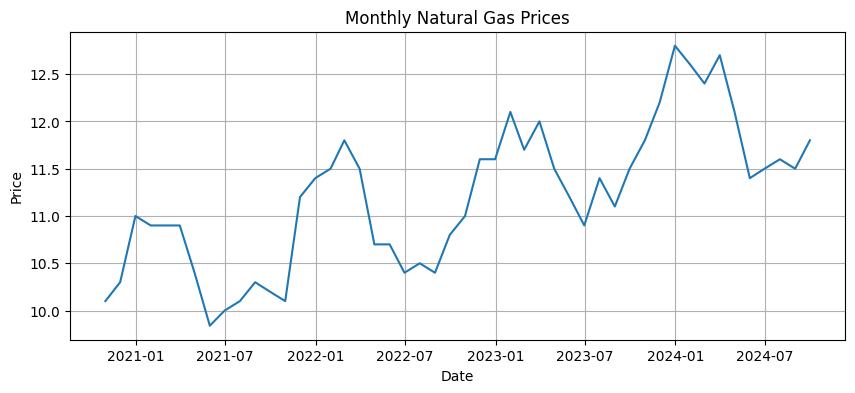

In [5]:
plt.figure(figsize=(10,4))
plt.plot(df["Dates"], df["Prices"])
plt.xlabel("Date")
plt.ylabel("Price")
plt.title("Monthly Natural Gas Prices")
plt.grid(True)
plt.show()


In [6]:
# Month extraction (NO index usage)
df["month"] = df["Dates"].dt.month
df["t"] = df["Dates"].map(pd.Timestamp.toordinal)


# Monthly seasonality
monthly_seasonality = (
    df.groupby("month")["Prices"].mean()
    - df["Prices"].mean()
)

# De-seasonalize
df["deseasonalized"] = df["Prices"] - df["month"].map(monthly_seasonality)

# Trend model on de-seasonalized prices
from sklearn.linear_model import LinearRegression

X = df[["t"]]
y = df["deseasonalized"]

trend_model = LinearRegression()
trend_model.fit(X, y)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


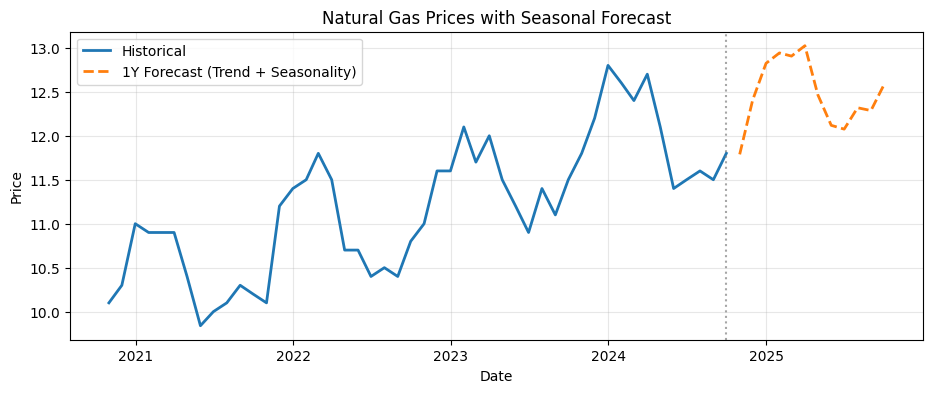

In [7]:
# Future dates (use Dates column, NOT index)
future_dates = pd.date_range(
    start=df["Dates"].iloc[-1] + pd.offsets.MonthEnd(1),
    periods=12,
    freq="ME"
)

future_t = future_dates.map(pd.Timestamp.toordinal)
future_months = future_dates.month

future_trend = trend_model.predict(
    pd.DataFrame({"t": future_t})
)
future_seasonality = future_months.map(monthly_seasonality)

future_prices = future_trend + future_seasonality.values

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(11,4))
plt.plot(df["Dates"], df["Prices"], label="Historical", linewidth=2)
plt.plot(
    future_dates,
    future_prices,
    linestyle="--",
    linewidth=2,
    label="1Y Forecast (Trend + Seasonality)"
)
plt.axvline(df["Dates"].iloc[-1], color="gray", linestyle=":", alpha=0.7)
plt.title("Natural Gas Prices with Seasonal Forecast")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [8]:
from scipy.interpolate import interp1d

hist_interp = interp1d(
    df["t"],
    df["Prices"],
    kind="linear",
    bounds_error=False
)

In [9]:
def estimate_gas_price(date_str):
    """
    Estimate natural gas price for a given date.
    Uses linear interpolation for historical dates
    and trend + seasonality extrapolation for future dates.
    """
    date = pd.to_datetime(date_str)
    t = date.toordinal()
    last_t = df["t"].iloc[-1]

    # Historical / in-sample
    if t <= last_t:
        return float(hist_interp(t))

    # Future (indicative)
    trend_price = trend_model.predict(
        pd.DataFrame({"t": [t]})
    )[0]

    seasonal_adj = monthly_seasonality.get(date.month, 0.0)

    return float(trend_price + seasonal_adj)


In [10]:
estimate_gas_price("2021-06-15")   # historical
estimate_gas_price("2024-09-30")   # boundary
estimate_gas_price("2025-03-31")   # future

13.023602935424073